# Расчёт проточной части газовой турбины (вариант с парциальным подводом)
**Михальцев В.Е., Моляков В.Д. «Теория и проектирование газовой турбины», ч. 1**
(МГТУ им. Баумана, 2006) — гл. 4–9, алгоритм расчёта проточной части (п. 1–153, стр. 84–93).

Исходные данные берутся **напрямую из `Turbinis-Cycle`**: при запуске этого блокнота
`cycle_link.load_cycle()` выполняет блокнот цикла в отдельном пространстве имён и забирает
оттуда параметры выбранной расчётной точки. Изменили что-то в цикле — перезапустите Calc,
и всё пересчитается.

Ход расчёта:
1. Исходные данные из цикла и «выбираемые» параметры книги.
2. Частота вращения и размеры (гл. 6, п. 1–12, 26–34): почему одной ступени мало.
3. Многоступенчатая турбина (п. 45–69) и расчёт ступеней (п. 70–145).
4. Параметры турбины в целом (п. 146–153) и сверка с циклом.
5. Профилирование лопаток по радиусу (гл. 7).
6. Решётки профилей: шаг, хорда, число лопаток (гл. 8).
7. Сводка и графики.

**Эта копия отличается парциальным подводом:** на ступенях из `ε_парц_ст` сопловой аппарат занимает только долю ε окружности,
лопатки получаются выше в 1/ε раз (стр. 45), растут потери на вентиляцию (формула Стодола, стр. 44).
Не учтены потери на краях дуги подвода (в книге формул нет).


In [16]:
%matplotlib inline
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for _p in (Path.cwd(), Path.cwd() / "Turbinis-Calc"):
    if (_p / "cycle_link.py").exists():
        sys.path.insert(0, str(_p))
from cycle_link import load_cycle

Ц = load_cycle()  # namespace блокнота Turbinis-Cycle (он не меняется)

## 1. Исходные данные из цикла
Давление и температура перед турбиной, расход газа, давление за турбиной, механический КПД и
свойства газа (c_p, k, α) — те же функции, что использует цикл.

In [17]:
R = Ц["R"]
calc_cp = Ц["calc_cp_kerosene"]  # c_p(T, α), Дж/(кг·К)
calc_k = Ц["calc_k_kerosene"]  # k(T, α)
р = Ц["р"]  # результат calc_tvd в выбранной точке цикла

α_г = float(р["α"])  # коэффициент избытка воздуха
T_г_полн = float(Ц["T_г_полн"])  # T*г, К
π_к = float(Ц["π_к_выб"])
p_г_полн = Ц["σ_г"] * Ц["σ_вх"] * Ц["p_а_полн"] * π_к  # p*г = σ_г σ_вх p*в π*к
p_т = Ц["π_с"] * Ц["p_а"]  # статическое давление за турбиной, Па
G_в = float(Ц["G_в_выб"])
g_т = float(р["g_т"])  # G_т/G_в (1+g_m)(1-g_ут-g_охл)
g_воз = float(Ц["g_воз"])
G_c1 = G_в * g_т  # расход через СА 1-й ступени, кг/с
G_л_ост = G_в * (g_т + g_воз)  # расход после возврата охлаждающего воздуха, кг/с
η_м = float(Ц["η_м_тур"])
σ_л_доп = float(Ц["σ_л_доп"])  # МПа
K_n = float(Ц["K_n"])
l_т_D_т = float(Ц["l_т_to_D_т"])
c_т_а_цикл = float(Ц["c_т"])  # скорость за турбиной, принятая в цикле (M_т)
n_н = Ц["n_н"]  # частота вала нагрузки, если задана
N_т_цикл = G_в * р["L_т"] * (g_т + g_воз) * η_м  # мощность турбины в цикле, Вт
η_т_полн_цикл = float(р["η_т"])

исх = pd.Series(
    {
        "T*г, К": T_г_полн,
        "p*г, кПа": p_г_полн / 1e3,
        "p_т (за турбиной), кПа": p_т / 1e3,
        "π_т = p*г/p_т": p_г_полн / p_т,
        "G_c1 (через СА 1-й ступени), кг/с": G_c1,
        "G после возврата охл. воздуха, кг/с": G_л_ост,
        "α (избыток воздуха)": α_г,
        "η_м": η_м,
        "N_т по циклу, кВт": N_т_цикл / 1e3,
        "η*т по циклу (принят)": η_т_полн_цикл,
        "c_т по циклу, м/с": c_т_а_цикл,
        "σ_л доп, МПа": σ_л_доп,
        "l_т/D_т": l_т_D_т,
        "n_н (вал нагрузки)": n_н,
    }
)
print(f"Расчётная точка цикла: «{Ц['выбор']}», π*к = {π_к:.2f}")
исх.to_frame("значение")

Расчётная точка цикла: «G_в», π*к = 10.00


,значение
"T*г, К",1250.000000
"p*г, кПа",962.881825
"p_т (за турбиной), кПа",105.352000
π_т = p*г/p_т,9.139663
"G_c1 (через СА 1-й ступени), кг/с",0.462464
"G после возврата охл. воздуха, кг/с",0.462464
α (избыток воздуха),3.699057
η_м,0.992500
"N_т по циклу, кВт",253.269352
η*т по циклу (принят),0.928346


## 2. Параметры, которые в книге «выбираются»
Значения — из рекомендаций книги (середины диапазонов); то, что есть в цикле, взято из цикла.
Все допущения собраны здесь — меняйте только эту ячейку.

In [18]:
# --- коэффициенты скорости (стр. 34-37) ---
φ = 0.96  # СА: 0,95...0,97
ψ = 0.94  # РК: книга числа не даёт, типично 0,92...0,96
# --- углы ---
α1_цель = 12.0  # град, угол выхода из СА 1-й ступени (>16-17°; у малых турбин 11-14°, стр. 34: для увеличения длины лопаток)
α1_мин = 11.0  # град, контроль нижней границы (малые турбины 11-14°)
α1_мин_корня = 11.0  # град: у корня >= 13...14°, для турбин малой мощности допустимо 11...12° (стр. 73)
закон_профилирования = "Γ"  # расчётный закон по радиусу: "Γ" (Γ1u = const) или "α1" (α1 = const)
α2_диап_пром = (70.0, 90.0)  # допуск α2 промежуточных ступеней (стр. 38)
α2_диап_посл = (89.0, 91.0)  # допуск α2 последней ступени: осевой выход потока (α2 = 90°)
α2_цель_посл = 90.0  # град, α2 последней ступени
κ_ca = 1.0  # c2a = κ·c1a (осевая скорость примерно постоянна)
# --- распределение теплоперепада по ступеням (п. 51-54) ---
y0 = 0.55  # оптимальное (u/c0) ступени, ρ_ср = 0,25...0,45 -> 0,55...0,6
μ = 0.9  # коэффициент использования скорости c2 следующей ступенью
y0_мин = 0.48  # нижняя граница y0 при подборе нагрузки последней ступени (чтобы у корня ρ >= ρ_корня_мин при α2 = 90°)
D1_к_Dт = 0.85  # D1/D_т: 1 -> постоянный средний диаметр; <1 удлиняет лопатки 1-й ступени
z_заданное = None  # None -> по формуле п. 54
# --- степень реактивности (стр. 58): ρ_ср = f(l/D) ---
ρ_таблица = ([1 / 9, 1 / 6, 1 / 4, 1 / 3], [0.2, 0.3, 0.4, 0.5])
ρ_макс = 0.6
ρ_корня_мин = 0.05  # у корня ρ >= 0,05...0,1
# --- потери ---
δ_отн = 0.005  # относительный радиальный зазор δ_л/l (0,007...0,01 без уплотнения; соты/бандаж - меньше, стр. 12, 62)
δ_мин = 0.3e-3  # м, минимальный абсолютный зазор (с сотовыми вставками после приработки <= 0,2 мм, стр. 12)
ε_парц_ст = {1: 0.6, 2: 0.8}  # степень парциальности по номерам ступеней (стр. 45); остальные = 1,0 (полный подвод)
# --- меридиональное сечение (стр. 61-62) ---
lb_c, lb_л = 2.25, 2.75  # удлинение (l/b_a) СА и РК
δа_к_ba = 0.22  # осевой зазор δ_a/b_a,c = 0,20...0,25
b_a_мин = 5e-3  # м, конструктивный минимум ширины венца (оценка, не из книги)
γ_доп = 20.0  # град, допустимый угол раскрытия сечения γ = γ_н+γ_в (до 25)
# --- прочее ---
η_л_ожид = 0.90  # п. 5: лопаточный КПД для оценки T_т
охл_ступеней = 0  # число охлаждаемых ступеней (для толщин кромок, гл. 8): турбина неохлаждаемая

## 3. Свойства газа и функции, общие для расчёта
c_p и k — **истинные** (по книге, стр. 15 и 24), а не средние 0...T из методички цикла.


In [19]:
def газ(T):
    """Истинные c_p и k при температуре T для продуктов сгорания с α из цикла (стр. 15, 24, рис. П1-П2).

    Функция цикла calc_cp_kerosene даёт СРЕДНЮЮ теплоёмкость c_pm в интервале 0 °C...T
    (методичка, Прил. 6). Истинная: c_p = d(c_pm·t)/dt = c_pm + t·dc_pm/dT, t = T - 273,15 °C.
    Показатель адиабаты: k = c_p/(c_p - R).
    """
    dT = 1.0
    c_pm = float(calc_cp(T, α_г))
    dc_pm = (float(calc_cp(T + dT, α_г)) - float(calc_cp(T - dT, α_г))) / (2 * dT)
    c_p = c_pm + (T - 273.15) * dc_pm
    return c_p, c_p / (c_p - R)


class НетРешения(Exception):
    pass


def ρ_табл(l_к_D):
    return float(np.interp(l_к_D, *ρ_таблица))


def cp_k_ступени(T0, H0):
    """п. 75-76: c_p и k по средней условной температуре T_у = T*0 - H0 φ²/(2 c_p)."""
    cp, k = газ(T0)
    for _ in range(50):
        T_у = T0 - H0 * φ**2 / (2 * cp)
        cp_н, k_н = газ(T_у)
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return cp, k


def H0_по_p(T0, p0, p2):
    """п. 140: располагаемый теплоперепад ступени при заданном p2."""
    cp, k = газ(T0)
    H0 = 0.0
    for _ in range(50):
        H0 = cp * T0 * (1 - (p2 / p0) ** ((k - 1) / k))
        cp_н, k_н = газ(T0 - H0 * φ**2 / (2 * cp))
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return H0

## 4. Частота вращения и размеры одноступенчатой турбины (гл. 6, п. 1–12, 26–34)
Сначала — первая оценка по статическому давлению за турбиной (вариант «задано p_т»).

In [20]:
# п. 1-4
π_г = p_г_полн / p_т
cp0, k0 = газ(0.5 * (T_г_полн + T_г_полн * π_г**-0.25))  # T_ср = 0,5(T*г + T_ту), T_ту = T*г π_т^(-1/4)
H_т = cp0 * T_г_полн * (1 - π_г ** ((1 - k0) / k0))  # (1)
c0_т = math.sqrt(2 * H_т)
# п. 5-9
T_т = T_г_полн - H_т * η_л_ожид / cp0
v_т = R * T_т / p_т
A_т0 = G_л_ост * v_т / c_т_а_цикл  # c_т.а берём из цикла (M_т)
# п. 10-12
n_max0 = math.sqrt(σ_л_доп / (K_n * A_т0))  # σ_л = k_n n² A_т
n_т0 = n_max0 if n_н is None else float(n_н)
# п. 45-47 (D_т по l/D) и 26-31 (оптимальный диаметр одной ступени)
D_т0 = math.sqrt(A_т0 / (math.pi * l_т_D_т))
u_т0 = math.pi * D_т0 * n_т0 / 60
u_η = y0 * c0_т  # п. 28-29
D_η = 60 * u_η / (math.pi * n_т0)  # п. 30
l_η = A_т0 / (math.pi * D_η)  # п. 31

print(f"π_т(стат.) = {π_г:.2f}, k = {k0:.4f}, c_p = {cp0:.0f} Дж/(кг·К), H_т = {H_т/1e3:.1f} кДж/кг")
print(f"T_т = {T_т:.0f} К, v_т = {v_т:.3f} м³/кг, A_т = {A_т0*1e4:.1f} см², n_т max = {n_max0:.0f} об/мин")
print(f"c0 = {c0_т:.0f} м/с; одна ступень: u_η = {u_η:.0f} м/с (при u_т = {u_т0:.0f} м/с), "
      f"D_η = {D_η*1e3:.0f} мм против D_т = {D_т0*1e3:.0f} мм, l_η = {l_η*1e3:.1f} мм")
if u_η > 400 or D_η > 1.5 * D_т0:
    print("ВЫВОД (замечание 1, стр. 94; п. 29, 32): одноступенчатая турбина нецелесообразна — проектируем многоступенчатую.")

π_т(стат.) = 9.14, k = 1.3368, c_p = 1141 Дж/(кг·К), H_т = 609.4 кДж/кг
T_т = 769 К, v_т = 2.099 м³/кг, A_т = 103.1 см², n_т max = 47765 об/мин
c0 = 1104 м/с; одна ступень: u_η = 607 м/с (при u_т = 277 м/с), D_η = 243 мм против D_т = 111 мм, l_η = 13.5 мм
ВЫВОД (замечание 1, стр. 94; п. 29, 32): одноступенчатая турбина нецелесообразна — проектируем многоступенчатую.


## 5. Ступень турбины (п. 70–129)
`ступень()` — полный расчёт одной ступени на среднем радиусе: треугольники скоростей,
параметры газа, потери в СА и РК, в радиальном зазоре, на трение и вентиляцию, КПД.
Давление за ступенью следует из располагаемого теплоперепада: p₂ = p*₀ (1 − H₀/(c_p T*₀))^(k/(k−1)).

In [21]:
def l_c_предел(l_л_пред, δ_a_пред):
    """Наибольшая высота СА при допустимом угле раскрытия γ_доп между сечениями (п. 64, 69).

    Участок: выход РК (i-1) -> выход СА (i), длина Δx = δ_a(РК) + b_a,c; γ_н = γ_в = γ_доп/2.
    """
    t = math.tan(math.radians(γ_доп / 2))
    l1 = l_л_пред + 2 * t * (δ_a_пред + b_a_мин)  # ширина венца = минимальной
    if l1 / lb_c <= b_a_мин:
        return l1
    return (l_л_пред + 2 * t * δ_a_пред) / (1 - 2 * t / lb_c)  # b_a,c = l_c/(l/b)_c


def ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, раскр_пред=None, ε=1.0):
    cp, k = cp_k_ступени(T0, H0)  # п. 75-76
    # --- сопловой аппарат (п. 36-42, 57-62) ---
    Hc = H0 * (1 - ρ)
    c1 = φ * math.sqrt(2 * Hc)
    T1 = T0 - Hc * φ**2 / cp
    T1_ад = T0 - Hc / cp
    p1 = p0 * (T1_ад / T0) ** (k / (k - 1))
    v1 = R * T1 / p1
    # п. 63: l_c = G v1 / (π D sinα1 c1) при заданном α1; у 2-й и далее ступеней высота СА
    # ограничена допустимым раскрытием контура, тогда α1 растёт (п. 43-44: α1 = arcsin(c1a/c1))
    l_c = G_c * v1 / (math.pi * D_c * ε * math.sin(math.radians(α1_град)) * c1)  # ε - степень парциальности
    if раскр_пред is not None:
        l_c = min(l_c, l_c_предел(*раскр_пред))
    c1a = G_c * v1 / (math.pi * D_c * ε * l_c)
    if c1a >= c1:
        raise НетРешения("c1a >= c1")
    sin_α1 = c1a / c1
    α1 = math.asin(sin_α1)
    c1u = c1 * math.cos(α1)
    # --- вход в РК (п. 84-88) ---
    u1 = math.pi * D_c * n / 60
    u2 = math.pi * D_л * n / 60
    w1 = math.sqrt(c1**2 + u1**2 - 2 * c1 * u1 * math.cos(α1))
    β1 = math.atan2(c1a, c1u - u1)
    Hл = ρ * H0 * T1 / T1_ад  # п. 86
    # --- выход из РК (п. 89-100) ---
    w2 = ψ * math.sqrt(w1**2 + 2 * Hл + u2**2 - u1**2)
    T2 = T1 - (w2**2 - w1**2) / (2 * cp) + (u2**2 - u1**2) / (2 * cp)
    T2_ад = T1 - Hл / cp
    p2 = p1 * (T2_ад / T1) ** (k / (k - 1))
    v2 = R * T2 / p2
    c2a = κ_ca * c1a
    if w2 <= c2a:
        raise НетРешения("w2 <= c2a")
    c2u = math.sqrt(w2**2 - c2a**2) - u2  # c2u = w2 cosβ2 - u2
    β2 = math.atan2(c2a, c2u + u2)
    α2 = math.degrees(math.atan2(c2a, c2u))
    c2 = math.hypot(c2a, c2u)
    l_л = G_л * v2 / (c2a * math.pi * D_л * ε)  # п. 95-96; при парциальном подводе поток занимает дугу ε
    # --- работа и КПД на окружности (п. 101-111) ---
    L_u = c1u * u1 + c2u * u2
    η_u = L_u / H0
    ξ_c = (φ**-2 - 1) * c1**2 / 2 / H0 * T2_ад / T1  # ξ'_c
    ξ_л = (ψ**-2 - 1) * w2**2 / 2 / H0
    ξ_в = c2**2 / 2 / H0
    η_u2 = 1 - ξ_c - ξ_л - ξ_в
    # --- радиальный зазор (п. 114-118) ---
    D_ср = 0.5 * (D_c + D_л)
    δ_л = max(δ_отн * l_л, δ_мин)
    h_з = 1.37 * (1 + 1.6 * ρ) * (1 + l_л / D_ср) * (δ_л / l_л) * L_u
    ξ_з = h_з / H0
    η_т1 = η_u - ξ_з
    η_л1 = η_т1 + ξ_в
    # --- трение и вентиляция, формула Стодола (п. 119-123) ---
    ρ_г = 0.5 * (1 / v1 + 1 / v2)
    u_ср = 0.5 * (u1 + u2)
    N_тв = (1.07 * D_ср**2 + 61 * (1 - ε) * D_ср * l_л) * (u_ср / 100) ** 3 * ρ_г * 1e3
    h_тв = N_тв / G_c
    ξ_тв = h_тв / H0
    η_т = η_т1 - ξ_тв
    η_л = η_л1 - ξ_тв
    L_т = H0 * η_т  # п. 124
    # --- параметры за ступенью (п. 125-129) ---
    T_ст = T2 + (h_з + h_тв) / cp
    T_ст_п = T_ст + c2**2 / (2 * cp)
    p_ст_п = p2 * (T_ст_п / T_ст) ** (k / (k - 1))
    H0_п = cp * T0 * (1 - (p_ст_п / p0) ** ((k - 1) / k))
    return dict(
        T0=T0, p0=p0, H0=H0, ρ=ρ, cp=cp, k=k, Hc=Hc, Hл=Hл,
        c1=c1, c1a=c1a, c1u=c1u, α1=math.degrees(α1), T1=T1, T1_ад=T1_ад, p1=p1, v1=v1, l_c=l_c,
        u1=u1, u2=u2, w1=w1, β1=math.degrees(β1), w2=w2, β2=math.degrees(β2), T2=T2, p2=p2, v2=v2,
        c2a=c2a, c2u=c2u, c2=c2, α2=α2, l_л=l_л,
        L_u=L_u, η_u=η_u, η_u2=η_u2, ξ_c=ξ_c, ξ_л=ξ_л, ξ_в=ξ_в, ξ_з=ξ_з, ξ_тв=ξ_тв, h_з=h_з, h_тв=h_тв,
        η_т=η_т, η_л=η_л, L_т=L_т, T_ст=T_ст, T_ст_п=T_ст_п, p_ст_п=p_ст_п, H0_п=H0_п, η_т_п=L_т / H0_п,
        D_c=D_c, D_л=D_л, G_c=G_c, G_л=G_л, δ_л=δ_л, ε=ε,
    )  # fmt: skip


def ρ_корня(r):
    """Реактивность у корня СА при профилировании Γ = const (формулы (71)-(73), стр. 70-71)."""
    k, cp, T0, p0, H0, p2 = r["k"], r["cp"], r["T0"], r["p0"], r["H0"], r["p2"]
    r_c = r["D_c"] / 2
    r1 = r_c - 0.5 * r["l_c"]
    M1u = r["c1u"] / math.sqrt(k * R * r["T1_ад"])
    p1 = r["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))
    T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
    return cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k))


def _ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, диап, α1_град, раскр_пред=None, проверка_корня=True, α2_цель=None, ε=1.0):
    """ρ по l/D (таблица стр. 58); если α2 вне допуска — меняем ρ и пересчитываем (п. 99)."""

    def расчёт(ρ):
        return ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, раскр_пред, ε)

    def α2_от(ρ):
        try:
            return расчёт(ρ)["α2"]
        except НетРешения:
            return 180.0

    ρ = ρ_табл(0.1)
    for _ in range(6):
        if α2_от(ρ) >= 180.0:
            break
        ρ_н = ρ_табл(расчёт(ρ)["l_л"] / D_л)
        if abs(ρ_н - ρ) < 0.003:
            break
        ρ = ρ_н
    if not диап[0] <= α2_от(ρ) <= диап[1]:
        цель = α2_цель if α2_цель is not None else диап[1] - 2.0  # α2 убывает с ростом ρ
        lo, hi = 0.02, ρ_макс
        for _ in range(60):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if α2_от(mid) > цель else (lo, mid)
        ρ = 0.5 * (lo + hi)
    if проверка_корня:
        # стр. 58: у корня лопатки ρ >= 0,05...0,1. Нулевая закрутка (α2 ~ 88°) у длинных лопаток даёт у корня ρ ~ 0 -
        # повышаем ρ_ср, пока не выполнится условие у корня (допуская остаточную закрутку, α2 >= диап[0])
        def корень(ρ_):
            try:
                r_ = расчёт(ρ_)
            except НетРешения:
                return None
            return ρ_корня(r_) if r_["α2"] >= диап[0] else None

        if (корень(ρ) or -1.0) < ρ_корня_мин:
            lo, hi = ρ, ρ_макс
            for _ in range(60):
                mid = 0.5 * (lo + hi)
                f = корень(mid)
                if f is not None and f < ρ_корня_мин:
                    lo = mid
                else:
                    hi = mid
            ρ = hi
    r = расчёт(ρ)
    r["ρ_табл"] = ρ_табл(r["l_л"] / D_л)
    return r


def ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, диап, α1_град, раскр_пред=None, проверка_корня=True, α2_цель=None, ε=1.0):
    """Как _ступень_авто, но α1 повышается, если при профилировании Γ = const он у корня падает ниже α1_мин_корня.

    У корня tg α1 = tg α1_ср · r_корня / r_ср (c1u·r = const), поэтому у длинных лопаток нужен больший α1_ср.
    """
    α1 = α1_град
    for _ in range(8):
        r = _ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, диап, α1, раскр_пред, проверка_корня=проверка_корня, α2_цель=α2_цель, ε=ε)
        r_ср, r_кор = r["D_c"] / 2, r["D_c"] / 2 - r["l_c"] / 2
        α1_нужен = math.degrees(math.atan(math.tan(math.radians(α1_мин_корня)) * r_ср / r_кор))
        α1_нужен += 0.15  # запас на сходимость
        if r["α1"] >= α1_нужен:
            break
        α1 = α1 + max(α1_нужен - r["α1"], 0.1)
    return r


## 6. Многоступенчатая турбина (п. 45–69, 130–145)
* Средний диаметр последней ступени — по A_т и l/D (п. 45–46), окружная скорость — по n_т.
* Число ступеней z — п. 54. Теплоперепад ступеней — из u/c₀ = y₀ (п. 55), с учётом
  подтока энергии c₂ предыдущей ступени (п. 130–134).
* Последняя ступень рассчитывается по давлению за турбиной p₂z = p_т цикла (п. 138–141).
  Расход воздуха G_в подбирается так, чтобы чистая мощность на валу (N_т − N_к)·η_р равнялась
  заданной N_зад: у проточной части книги КПД ниже цикловой оценки, поэтому расход получается больше.
* Высота СА: l_c по заданному α₁ (п. 63); если это даёт раскрытие контура больше γ_доп
  (п. 64, 69), высота ограничивается, а α₁ получается из неразрывности (п. 43–44).

Площадь A_т (п. 8–9) была выбрана по c_т.а из цикла. После расчёта ступеней фактическая
площадь за последней ступенью может отличаться, поэтому A_т, n_т max и D_т уточняются
итерацией до совпадения (σ_л при этом остаётся равным допустимому).

In [22]:
p_кон = p_т  # давление за последней ступенью; подбирается ниже из условия N_вал = N_зад


def турбина(z, n, D1, D_т):
    D_гр = np.linspace(D1, D_т, z + 1)
    res = []
    for i in range(1, z + 1):
        D_c, D_л = float(D_гр[i - 1]), float(D_гр[i])
        u = math.pi * D_c * n / 60
        раскр_пред = None
        if i == 1:  # п. 57-63
            T0, p0, G_c, G_л = T_г_полн, p_г_полн, G_c1, G_c1
            H0 = u**2 / (2 * y0**2)
        else:  # п. 130-134
            пр = res[-1]
            T0 = пр["T_ст_п"]
            p0 = пр["p2"] * (1 + (μ * пр["c2"]) ** 2 / (2 * пр["cp"] * пр["T_ст"])) ** (пр["k"] / (пр["k"] - 1))
            G_c = G_л = G_л_ост
            H_i = u**2 / (2 * y0**2) - (μ * пр["c2"]) ** 2 / 2
            H0 = H_i * (1 + (1 - μ**2) * пр["c2"] ** 2 / (2 * пр["cp"] * T0)) + (μ * пр["c2"]) ** 2 / 2
            раскр_пред = (пр["l_л"], δа_к_ba * max(пр["l_л"] / lb_л, b_a_мин))
        диап = α2_диап_пром
        if i == z:  # п. 138-141: p2z = p_т
            if p0 <= p_кон * 1.02:
                raise НетРешения("давление перед последней ступенью не выше p_т: z слишком велико")
            H0 = H0_по_p(T0, p0, p_кон)
            диап = α2_диап_посл
        res.append(ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, диап, α1_цель, раскр_пред, проверка_корня=(i != z), α2_цель=(α2_цель_посл if i == z else None), ε=ε_парц_ст.get(i, 1.0)))
    return res


y0_баз = y0


def подобрать_z(z0, n, D1, D_т):
    """z по п. 54; если последняя ступень получилась нерасчётно малой/большой - меняем z.

    Последняя ступень: осевой выход (α2 = 90°) и ρ у корня >= ρ_корня_мин (стр. 58). При Γ = const для длинной лопатки
    это возможно только при умеренной нагрузке последней ступени, поэтому при необходимости уменьшаем y0 = u/c0
    ступеней 1...z-1: они берут больший теплоперепад, а на последнюю остаётся меньше.
    """
    global y0
    y0 = y0_баз
    z = z0
    for _ in range(12):
        try:
            ст = турбина(z, n, D1, D_т)
        except НетРешения:
            z -= 1
            continue
        отн = ст[-1]["H0"] / ст[0]["H0"] if z > 1 else 1.0
        if z > 1 and отн < 0.3:
            z -= 1
            continue
        if отн > 1.6:
            z += 1
            continue
        break
    else:
        raise RuntimeError("не удалось подобрать число ступеней")
    while ρ_корня(ст[-1]) < ρ_корня_мин - 1e-3 and y0 > y0_мин:
        y0 -= 0.005
        try:
            ст = турбина(z, n, D1, D_т)
        except НетРешения:
            y0 += 0.005
            ст = турбина(z, n, D1, D_т)
            break
    return z, ст


def решить(p_к):
    """Полный расчёт турбины (итерация по A_т) при давлении за последней ступенью p_к."""
    global p_кон
    p_кон = p_к
    A_т = A_т0
    c2_ср = 0.5 * c_т_а_цикл  # п. 52: начальная оценка, затем - по результатам расчёта
    итерации = []
    n_т, D_т, u_т, A_факт, z, ступени = n_т0, D_т0, u_т0, A_т0, 0, []
    for it in range(60):
        n_max = math.sqrt(σ_л_доп / (K_n * A_т))
        n_т = n_max if n_н is None else float(n_н)
        D_т = math.sqrt(A_т / (math.pi * l_т_D_т))  # п. 46
        D1 = D1_к_Dт * D_т  # п. 48
        u_т = math.pi * D_т * n_т / 60  # п. 47
        u_ср = 0.5 * (u_т + math.pi * D1 * n_т / 60)  # п. 49-50
        μc = μ * c2_ср
        z_расч = (c0_т**2 / μc**2 - 1) / (u_ср**2 / (μc**2 * y0**2) - 1)  # п. 54
        z0 = z_заданное or max(1, math.ceil(z_расч))
        z, ступени = подобрать_z(z0, n_т, D1, D_т)
        A_факт = math.pi * ступени[-1]["D_л"] * ступени[-1]["l_л"]
        c2_ср = float(np.mean([s["c2"] for s in ступени[:-1]] or [ступени[-1]["c2"]]))
        итерации.append((it, A_т, n_т, D_т, z_расч, z, A_факт))
        if abs(A_факт - A_т) / A_т < 1e-4:
            break
        A_т = 0.5 * (A_т + A_факт)
    return dict(A_т=A_т, n_т=n_т, D_т=D_т, u_т=u_т, A_факт=A_факт, z=z, ступени=ступени, итерации=итерации)


def задать_расход(G):
    """Меняем расход воздуха: G_в, расходы через СА/РК и начальная оценка A_т пропорциональны ему."""
    global G_в, G_c1, G_л_ост, A_т0
    k = G / G_в
    G_в, G_c1, G_л_ост, A_т0 = G, G_c1 * k, G_л_ост * k, A_т0 * k


def N_на_валу(G):
    """Мощность на валу (п. 146, 153): N_в = (N_т - N_к) η_р, как в цикле; p за последней ступенью = p_т."""
    задать_расход(G)
    r = решить(p_т)
    ст = r["ступени"]
    g = [s["G_c"] / G_c1 for s in ст]
    N_турб = sum(gi * s["L_т"] for gi, s in zip(g, ст)) * G_c1 * η_м
    return (N_турб - G_в * float(р["L_к"])) * float(Ц["η_р"]), r


# Расход воздуха из цикла получен при цикловом η*т; у проточной части книги КПД иной, поэтому
# подбираем G_в так, чтобы чистая мощность на валу была равна заданной (давление за турбиной = p_т цикла)
N_зад = float(Ц["N_зад"])
G_в_цикл = G_в
lo, hi = 0.8 * G_в_цикл, 1.6 * G_в_цикл  # N_вал растёт с G_в
N_lo, _ = N_на_валу(lo)
N_hi, _ = N_на_валу(hi)
assert N_lo < N_зад < N_hi, f"N_зад вне диапазона подбора: {N_lo/1e3:.1f}...{N_hi/1e3:.1f} кВт"
for _ in range(40):
    mid = 0.5 * (lo + hi)
    N_mid, _r = N_на_валу(mid)
    lo, hi = (mid, hi) if N_mid < N_зад else (lo, mid)
    if abs(N_mid - N_зад) < 1e-5 * N_зад:
        break
N_вал_подбор, _r = N_на_валу(mid)
p_кон = p_т
A_т, n_т, D_т, u_т, A_факт, z, ступени, итерации = (_r[k] for k in ("A_т", "n_т", "D_т", "u_т", "A_факт", "z", "ступени", "итерации"))

σ_л_факт = K_n * n_т**2 * A_факт
print(pd.DataFrame(итерации, columns=["итер.", "A_т, м²", "n_т, об/мин", "D_т, м", "z (п.54)", "z", "A_2a факт., м²"]).to_string(index=False))
print(f"Подобран расход воздуха G_в = {G_в:.4f} кг/с (по циклу {G_в_цикл:.4f} кг/с, {(G_в/G_в_цикл-1)*100:+.1f} %), p за последней ступенью = p_т = {p_т/1e3:.2f} кПа, N_вал = {N_вал_подбор/1e3:.2f} кВт")
print(f"\nz = {z}, n_т = {n_т:.0f} об/мин, D_т = {D_т*1e3:.1f} мм, u_т = {u_т:.0f} м/с, σ_л = {σ_л_факт:.0f} МПа (доп. {σ_л_доп:.0f})")

 итер.  A_т, м²  n_т, об/мин   D_т, м  z (п.54)  z  A_2a факт., м²
     0 0.011243 45747.825148 0.115587  5.251938  6        0.012373
     1 0.011808 44640.064109 0.118455  5.236855  6        0.012353
     2 0.012080 44133.216155 0.119816  5.235954  6        0.012250
     3 0.012165 43978.900978 0.120236  5.333055  6        0.012250
     4 0.012208 43902.270434 0.120446  5.332812  6        0.012250
     5 0.012229 43864.233121 0.120550  5.332695  6        0.012250
     6 0.012239 43845.468164 0.120602  5.332638  6        0.012250
     7 0.012245 43836.202326 0.120627  5.332610  6        0.012250
     8 0.012247 43831.624924 0.120640  5.332597  6        0.012250
     9 0.012248 43829.363141 0.120646  5.332590  6        0.012250
    10 0.012249 43828.245427 0.120649  5.332587  6        0.012250
Подобран расход воздуха G_в = 0.4987 кг/с (по циклу 0.4575 кг/с, +9.0 %), p за последней ступенью = p_т = 105.35 кПа, N_вал = 110.00 кВт

z = 6, n_т = 43828 об/мин, D_т = 120.6 мм, u_т = 277 м/с, 

## 7. Результаты по ступеням (п. 70–145)

In [23]:
имена = [
    ("ε", "ε (парциальность)", "-", 1),
    ("H0", "H₀ ступени", "кДж/кг", 1e-3),
    ("ρ", "ρ (реактивность)", "-", 1),
    ("c1", "c₁", "м/с", 1),
    ("α1", "α₁", "град", 1),
    ("β1", "β₁", "град", 1),
    ("w1", "w₁", "м/с", 1),
    ("w2", "w₂", "м/с", 1),
    ("β2", "β₂", "град", 1),
    ("c2", "c₂", "м/с", 1),
    ("α2", "α₂", "град", 1),
    ("u1", "u₁", "м/с", 1),
    ("T1", "T₁", "К", 1),
    ("p1", "p₁", "кПа", 1e-3),
    ("p2", "p₂", "кПа", 1e-3),
    ("T2", "T₂", "К", 1),
    ("l_c", "l_c (СА)", "мм", 1e3),
    ("l_л", "l_л (РК)", "мм", 1e3),
    ("L_u", "L_u", "кДж/кг", 1e-3),
    ("η_u", "η_u (п. 102)", "-", 1),
    ("η_u2", "η_u (п. 111)", "-", 1),
    ("ξ_c", "ξ'_c", "-", 1),
    ("ξ_л", "ξ_л", "-", 1),
    ("ξ_в", "ξ_в", "-", 1),
    ("ξ_з", "ξ_з (рад. зазор)", "-", 1),
    ("ξ_тв", "ξ_т.в", "-", 1),
    ("η_т", "η_т ступени", "-", 1),
    ("η_л", "η_л ступени", "-", 1),
    ("η_т_п", "η*_т ступени", "-", 1),
    ("L_т", "L_т", "кДж/кг", 1e-3),
]
табл_ст = pd.DataFrame(
    {f"ст. {i}": [s[к] * м for к, _, _, м in имена] for i, s in enumerate(ступени, 1)},
    index=pd.MultiIndex.from_tuples([(н, е) for _, н, е, _ in имена], names=["параметр", "ед."]),
)
табл_ст.style.format("{:.4g}")

,,ст. 1,ст. 2,ст. 3,ст. 4,ст. 5,ст. 6
параметр,ед.,,,,,,
ε (парциальность),-,0.6,0.8,1,1,1,1
H₀ ступени,кДж/кг,98.59,104.5,110.6,116.8,123.2,95.29
ρ (реактивность),-,0.267,0.2529,0.2522,0.2823,0.3406,0.4328
c₁,м/с,364.9,379.4,390.4,393.1,387,315.6
α₁,град,13.01,12.71,12.65,12.86,13.53,16.12
β₁,град,34.33,33.15,32.97,34.52,38.65,69.21
w₁,м/с,145.6,152.7,157,154.3,145,93.75
w₂,м/с,261.5,265.6,272.8,287.8,310.6,290.4
β₂,град,18.31,18.32,18.26,17.69,16.95,17.57


## 8. Турбина в целом (п. 146–153) и сверка с циклом

In [24]:
g_i = [s["G_c"] / G_c1 for s in ступени]
L_тΣ = sum(g * s["L_т"] for g, s in zip(g_i, ступени))  # п. 146
H_т_ст = H_т  # п. 147: по истинному p_т
η_т_турб = L_тΣ / H_т_ст  # п. 148
h_вz = ступени[-1]["c2"] ** 2 / 2
η_л_турб = (L_тΣ + h_вz) / H_т_ст  # п. 149
p_т_полн = ступени[-1]["p_ст_п"]  # p*_т за последней ступенью
cp_т, k_т = газ(0.5 * (T_г_полн + ступени[-1]["T_ст_п"]))
H_т_полн = cp_т * T_г_полн * (1 - (p_т_полн / p_г_полн) ** ((k_т - 1) / k_т))  # п. 150
η_т_полн = L_тΣ / H_т_полн  # п. 151
N_т = L_тΣ * G_c1 * η_м  # п. 153
# мощность на валу (в редуктор и на винт): N_в = (N_т - N_к) η_р, как в цикле
N_к = G_в * float(р["L_к"])
N_вал = (N_т - N_к) * float(Ц["η_р"])
N_вал_цикл = (N_т_цикл - G_в_цикл * float(р["L_к"])) * float(Ц["η_р"])  # при расходе цикла

сверка = pd.DataFrame(
    {
        "по книге (Calc)": [N_вал / 1e3, N_т / 1e3, G_в, η_т_полн, p_т_полн / 1e3, ступени[-1]["c2"], ступени[-1]["T_ст_п"]],
        "по циклу (Cycle)": [Ц["N_зад"] / 1e3, N_т_цикл / 1e3, G_в_цикл, η_т_полн_цикл, Ц["р"]["π_с_полн"] * Ц["p_а"] / 1e3, c_т_а_цикл, float(р["T_т"])],
    },
    index=["N на валу, кВт", "N_т, кВт", "G_в, кг/с", "η*_т", "p*_т за турбиной, кПа", "скорость за турбиной, м/с", "T*_т, К"],
)
сверка["расхождение, %"] = (сверка.iloc[:, 0] / сверка.iloc[:, 1] - 1) * 100
print(f"L_тΣ = {L_тΣ/1e3:.1f} кДж/кг, H_т = {H_т_ст/1e3:.1f} кДж/кг, η_т = {η_т_турб:.3f}, η_л = {η_л_турб:.3f}, "
      f"H*_т = {H_т_полн/1e3:.1f} кДж/кг, η*_т = {η_т_полн:.3f}")
print(f"N_т = {N_т/1e3:.1f} кВт (η_м = {η_м:.4f}), N_к = {N_к/1e3:.1f} кВт, "
      f"на валу N_в = {N_вал/1e3:.1f} кВт (задано {Ц['N_зад']/1e3:.0f} кВт)")
сверка.style.format("{:.4g}")

L_тΣ = 531.7 кДж/кг, H_т = 609.4 кДж/кг, η_т = 0.873, η_л = 0.879, H*_т = 606.8 кДж/кг, η*_т = 0.876
N_т = 266.0 кВт (η_м = 0.9925), N_к = 154.4 кВт, на валу N_в = 110.0 кВт (задано 110 кВт)


,по книге (Calc),по циклу (Cycle),"расхождение, %"
"N на валу, кВт",110,110,0.0007594
"N_т, кВт",266,253.3,5.04
"G_в, кг/с",0.4987,0.4575,9.014
η*_т,0.8762,0.9283,-5.616
"p*_т за турбиной, кПа",107.2,107.6,-0.3873
"скорость за турбиной, м/с",87.65,94.1,-6.861
"T*_т, К",786.4,731.9,7.45


## 9. Меридиональное сечение проточной части (п. 64–69, стр. 61–62)

In [25]:
контур = []  # сечения по ходу газа: x, r_наружный, r_внутренний
x = 0.0
геом = []
for i, s in enumerate(ступени):
    b_c = max(s["l_c"] / lb_c, b_a_мин)
    b_л = max(s["l_л"] / lb_л, b_a_мин)
    δ_a = δа_к_ba * b_c
    геом.append(dict(b_c=b_c, b_л=b_л, δ_a=δ_a, δ_a_л=δа_к_ba * b_л))
    if i == 0:
        контур.append((x, s["D_c"] / 2 + s["l_c"] / 2, s["D_c"] / 2 - s["l_c"] / 2, f"СА{i+1} выход"))
    x_л = x + δ_a + b_л
    контур.append((x_л, s["D_л"] / 2 + s["l_л"] / 2, s["D_л"] / 2 - s["l_л"] / 2, f"РК{i+1} выход"))
    x = x_л
    if i + 1 < len(ступени):
        сл = ступени[i + 1]
        b_c2 = max(сл["l_c"] / lb_c, b_a_мин)
        x = x + геом[-1]["δ_a_л"] + b_c2
        контур.append((x, сл["D_c"] / 2 + сл["l_c"] / 2, сл["D_c"] / 2 - сл["l_c"] / 2, f"СА{i+2} выход"))
контур_df = pd.DataFrame(контур, columns=["x", "r_н", "r_в", "сечение"])
γ_н = np.degrees(np.arctan(np.diff(контур_df.r_н) / np.diff(контур_df.x)))
γ_в = np.degrees(np.arctan(-np.diff(контур_df.r_в) / np.diff(контур_df.x)))
участки = pd.DataFrame(
    {"участок": [f"{контур_df.сечение[j]} → {контур_df.сечение[j+1]}" for j in range(len(γ_н))],
     "γ_н, град": γ_н, "γ_в, град": γ_в, "γ = γ_н+γ_в, град": γ_н + γ_в}
)
print(f"Длина проточной части {контур_df.x.iloc[-1]*1e3:.0f} мм; максимальный угол раскрытия γ = {участки['γ = γ_н+γ_в, град'].max():.1f}° (допуск {γ_доп:.0f}°, не более 25°)")
участки.style.format({"γ_н, град": "{:.1f}", "γ_в, град": "{:.1f}", "γ = γ_н+γ_в, град": "{:.1f}"})

Длина проточной части 100 мм; максимальный угол раскрытия γ = 20.0° (допуск 20°, не более 25°)


,участок,"γ_н, град","γ_в, град","γ = γ_н+γ_в, град"
0,СА1 выход → РК1 выход,14.8,-10.9,3.9
1,РК1 выход → СА2 выход,-6.9,-6.9,-13.8
2,СА2 выход → РК2 выход,15.7,-11.4,4.3
3,РК2 выход → СА3 выход,-2.3,-2.3,-4.6
4,СА3 выход → РК3 выход,16.2,-10.9,5.4
5,РК3 выход → СА4 выход,10.0,10.0,20.0
6,СА4 выход → РК4 выход,14.8,-6.7,8.1
7,РК4 выход → СА5 выход,10.0,10.0,20.0
8,СА5 выход → РК5 выход,14.3,-1.6,12.6
9,РК5 выход → СА6 выход,10.0,10.0,20.0


## 10. Профилирование лопаток по радиусу (гл. 7)
Для каждой ступени — корневое, среднее и периферийное сечения на выходе из СА и из РК.
* **Постоянная циркуляция** (Γ₁ᵤ = const, формулы 67–82): c₁ᵤ·r = const, c₁ₐ = const,
  давление по (71), реактивность по (72)–(73), углы по (75)–(82).
* **Постоянный угол α₁** (разд. 7.3): c ∝ r^(−cos²α₁).
  Для выхода из РК книга формул не даёт — принято L_u = const по радиусу (допущение): c₂ᵤ = (L_u − c₁ᵤu₁)/u₂.

**Расчётный закон — Γ = const** (`закон_профилирования` в ячейке с допущениями); закон α₁ = const показан для сравнения.
У длинных лопаток α₁ ср повышается ступенью так, чтобы у корня α₁ ≥ `α1_мин_корня` (tg α₁кор = tg α₁ср · r_кор / r_ср).


In [26]:
def профиль(s, метод):
    """Параметры на радиусах корня / среднем / периферии для одной ступени."""
    k, cp, T0, p0, H0, p2, n = s["k"], s["cp"], s["T0"], s["p0"], s["H0"], s["p2"], n_т
    r_c, r_л = s["D_c"] / 2, s["D_л"] / 2
    out = {}
    for имя, f_c, f_л in (("корень", -0.5, -0.5), ("средний", 0.0, 0.0), ("периферия", 0.5, 0.5)):
        r1 = r_c + f_c * s["l_c"]
        r2 = r_л + f_л * s["l_л"]
        u1 = math.pi * n * r1 / 30
        u2 = math.pi * n * r2 / 30
        if метод == "Γ":
            c1u = s["c1u"] * r_c / r1
            c1a = s["c1a"]
            a1 = math.sqrt(k * R * s["T1_ад"])
            M1u = s["c1u"] / a1
            p1 = s["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))  # (71)
            c2u = s["c2u"] * r_л / r2
            c2a = s["c2a"]
        else:  # α1 = const
            m = math.cos(math.radians(s["α1"])) ** 2
            q = (r_c / r1) ** m
            c1u, c1a = s["c1u"] * q, s["c1a"] * q
            c1ад = math.hypot(c1u, c1a) / φ
            p1 = p0 * (1 - c1ад**2 / (2 * cp * T0)) ** (k / (k - 1))
            c2a = s["c2a"]
            c2u = (s["L_u"] - c1u * u1) / u2 if u2 else s["c2u"]
        T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
        ρ_r = cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k))  # (72)-(73)
        out[имя] = {
            "r, мм": r1 * 1e3,
            "c₁, м/с": math.hypot(c1u, c1a),
            "p₁/p*₀": p1 / p0,
            "ρ": ρ_r,
            "α₁, град": math.degrees(math.atan2(c1a, c1u)),
            "β₁, град": math.degrees(math.atan2(c1a, c1u - u1)),
            "α₂, град": math.degrees(math.atan2(c2a, c2u)),
            "β₂, град": math.degrees(math.atan2(c2a, c2u + u2)),
        }
    return pd.DataFrame(out)


профили = {м: [профиль(s, м) for s in ступени] for м in ("Γ", "α1")}
пред = []
список = профили[закон_профилирования]
м = закон_профилирования  # предупреждения - только по расчётному закону; второй закон справочный
if True:
    for i, df in enumerate(список, 1):
        if df.loc["α₁, град", "корень"] < α1_мин_корня:
            пред.append(f"{м}, ст. {i}: α₁ у корня = {df.loc['α₁, град', 'корень']:.1f}° < {α1_мин_корня:.0f}° (стр. 73)")
        if df.loc["ρ", "корень"] < ρ_корня_мин:
            пред.append(f"{м}, ст. {i}: ρ у корня = {df.loc['ρ', 'корень']:.3f} < {ρ_корня_мин}")
print("Предупреждения профилирования:" if пред else "Критерии профилирования выполнены.")
print("\n".join("  - " + t for t in пред))
сводка_профиль = pd.concat(
    {f"ст. {i} ({м})": df.loc[["α₁, град", "β₁, град", "ρ", "α₂, град", "β₂, град"]] for м in ("Γ", "α1") for i, df in enumerate(профили[м], 1)}
)
сводка_профиль.style.format("{:.3g}")

Критерии профилирования выполнены.



## 11. Решётки профилей: шаг, хорда, число лопаток (гл. 8, аналитическая часть)
Построение самого контура профиля (графическое) здесь не выполняется. Считаем:
углы лопаток с учётом отставания потока δ, угол установки γ, оптимальный относительный шаг,
хорду, шаг, число лопаток (в соседних решётках — взаимно простые), горло a ≈ t·sinα₁.

In [27]:
def отставание(M, угол):
    """δ, град (стр. 78): зависит от числа Маха и угла выхода."""
    δ06 = np.interp(угол, [17.5, 25.0, 35.0], [0.9, 1.5, 3.5])  # при M = 0,6
    δ_95 = 1 / 3  # 20' при M >= 0,95
    return float(np.interp(M, [0.6, 0.95], [δ06, δ_95]))


def t_к_b(β1, β2, K, c_max):
    s = β1 + β2
    if s >= 180 or β2 <= 0:
        return 0.75
    t_b = K * (180 / (180 - s) * math.sin(math.radians(β1)) / math.sin(math.radians(β2))) ** (1 / 3) * (1 - c_max)
    return float(np.clip(t_b, 0.55, 0.9))


def γ_установки(β1, β2):
    d = β1 - β2
    return 70 - 0.127 * d - 0.0041 * d**2


def взаимно_простые(z_c, t_л, D):
    """Число лопаток РК, ближайшее к πD/t и взаимно простое с z_c."""
    z0 = round(math.pi * D / t_л)
    for d in (0, 1, -1, 2, -2, 3, -3):
        if math.gcd(z_c, z0 + d) == 1:
            return z0 + d
    return z0


решётки = []
for i, (s, g) in enumerate(zip(ступени, геом), 1):
    охл = i <= охл_ступеней
    D = 0.5 * (s["D_c"] + s["D_л"])
    # --- СА ---
    a1 = math.sqrt(s["k"] * R * s["T1"])
    M_c1 = s["c1"] / a1
    δ_c = отставание(M_c1, s["α1"])
    α1_л = s["α1"] - δ_c
    β_вх_c = 90.0 if i == 1 else ступени[i - 2]["α2"]
    γ_c = γ_установки(β_вх_c, α1_л)
    b_c = g["b_c"] / math.sin(math.radians(γ_c))
    tb_c = t_к_b(β_вх_c, α1_л, 0.45, 0.2 if охл else 0.13)
    ε_i = s["ε"]
    z_c = max(3, round(ε_i * math.pi * D / (tb_c * b_c)))  # сопла только в дуге ε
    t_c = ε_i * math.pi * D / z_c
    a_c = t_c * math.sin(math.radians(α1_л))
    s2_c = (0.11 if охл else 0.055) * a_c
    # --- РК ---
    w_зв = math.sqrt(s["k"] * R * s["T2"])
    M_w2 = s["w2"] / w_зв
    δ_л = отставание(M_w2, s["β2"])
    β2_л = s["β2"] - δ_л
    γ_л = γ_установки(s["β1"], β2_л)
    b_л = g["b_л"] / math.sin(math.radians(γ_л))
    tb_л = t_к_b(s["β1"], β2_л, 0.60, 0.2 if охл else 0.11)
    z_л = взаимно_простые(z_c, tb_л * b_л, D)
    t_л = math.pi * D / z_л
    a_л = t_л * math.sin(math.radians(β2_л))
    s2_л = (0.17 if охл else 0.07) * a_л
    решётки.append(
        {
            "M_c1": M_c1, "δ_c, град": δ_c, "α1л, град": α1_л, "γ_c, град": γ_c, "b_c, мм": b_c * 1e3,
            "t/b_c": tb_c, "z_c": z_c, "t_c, мм": t_c * 1e3, "a_c, мм": a_c * 1e3, "s2_c, мм": s2_c * 1e3,
            "r1_c, мм": 0.035 * g["b_c"] * 1e3, "l/b_c (по хорде)": s["l_c"] / b_c,
            "M_w2": M_w2, "δ_л, град": δ_л, "β2л, град": β2_л, "γ_л, град": γ_л, "b_л, мм": b_л * 1e3,
            "t/b_л": tb_л, "z_л": z_л, "t_л, мм": t_л * 1e3, "a_л, мм": a_л * 1e3, "s2_л, мм": s2_л * 1e3,
            "r1_л, мм": 0.035 * g["b_л"] * 1e3, "l/b_л (по хорде)": s["l_л"] / b_л,
        }
    )  # fmt: skip
решётки_df = pd.DataFrame(решётки, index=[f"ст. {i}" for i in range(1, len(ступени) + 1)]).T
решётки_df.style.format("{:.3g}")

,ст. 1,ст. 2,ст. 3,ст. 4,ст. 5,ст. 6
M_c1,0.543,0.58,0.617,0.645,0.663,0.562
"δ_c, град",0.9,0.9,0.872,0.827,0.798,0.9
"α1л, град",12.1,11.8,11.8,12,12.7,15.2
"γ_c, град",35.2,38.1,36.5,36.7,41,48.8
"b_c, мм",10.7,9.16,9.48,12.1,14.4,17
t/b_c,0.871,0.861,0.87,0.865,0.831,0.755
z_c,21,34,42,34,31,29
"t_c, мм",9.34,7.92,8.23,10.5,11.8,12.9
"a_c, мм",1.96,1.62,1.68,2.18,2.59,3.39
"s2_c, мм",0.108,0.0891,0.0924,0.12,0.143,0.186


## 12. Контроль расчёта
Жёсткие проверки (ошибка = неверный расчёт) и мягкие замечания (проектное решение пользователя).

In [28]:
# --- жёсткие проверки ---
for i, s in enumerate(ступени, 1):
    assert abs(s["η_u"] - s["η_u2"]) < 1e-6, f"ст. {i}: η_u по п. 102 и п. 111 не совпали"
    T2_полн = s["T2"] + s["c2"] ** 2 / (2 * s["cp"])
    assert abs(s["L_u"] - s["cp"] * (s["T0"] - T2_полн)) < 1e-6 * s["L_u"], f"ст. {i}: нарушен баланс энергии"
assert abs(ступени[-1]["p2"] - p_кон) < 1e-6 * p_кон, "давление за последней ступенью ≠ p_т"
assert abs(N_вал / N_зад - 1) < 1e-3, "мощность на валу не равна заданной"
assert abs(A_факт - A_т) / A_т < 1e-3, "итерация по A_т не сошлась"
if n_н is None:
    assert σ_л_факт <= σ_л_доп * 1.005, "σ_л превышает допустимое"
for i, s in enumerate(ступени, 1):
    диап = α2_диап_посл if i == len(ступени) else α2_диап_пром
    assert диап[0] - 0.5 <= s["α2"] <= диап[1] + 0.5, f"ст. {i}: α2 = {s['α2']:.1f}° вне допуска {диап}"
print("Жёсткие проверки пройдены: η_u (п. 102 = п. 111), баланс энергии каждой ступени, p₂z = p_т, N_вал = N_зад, σ_л, α₂.")

# --- мягкие замечания ---
зам = []
нет = lambda усл: [i for i, s in enumerate(ступени, 1) if усл(s)]  # номера ступеней по условию
if нет(lambda s: s["α1"] < α1_мин):
    зам.append(f"α₁ < {α1_мин}° в ступенях {нет(lambda s: s['α1'] < α1_мин)}")
if нет(lambda s: s["l_c"] < 40e-3):
    зам.append(
        f"короткие лопатки (l_c < 40...50 мм) в ступенях {нет(lambda s: s['l_c'] < 40e-3)}: "
        f"l_c = {ступени[0]['l_c']*1e3:.1f}...{ступени[-1]['l_c']*1e3:.1f} мм — концевые потери выше; φ и ψ по длине лопатки не корректировались"
    )
if нет(lambda s: s["ξ_з"] > 0.05):
    зам.append(
        f"потери в радиальном зазоре ξ_з > 5 % в ступенях {нет(lambda s: s['ξ_з'] > 0.05)}: "
        f"ξ_з(1-я) = {ступени[0]['ξ_з']:.3f} при δ_л = {ступени[0]['δ_л']*1e3:.2f} мм, l_л = {ступени[0]['l_л']*1e3:.1f} мм (бандаж/соты не учтены)"
    )
if u_т > 400:
    зам.append(f"u_т = {u_т:.0f} м/с > 400 м/с")
if участки["γ = γ_н+γ_в, град"].max() > γ_доп + 0.05:
    зам.append(f"угол раскрытия проточной части {участки['γ = γ_н+γ_в, град'].max():.1f}° > {γ_доп}°")
if abs(N_вал / Ц["N_зад"] - 1) > 0.02:
    зам.append(f"мощность на валу {N_вал/1e3:.1f} кВт вместо заданной {Ц['N_зад']/1e3:.0f} кВт ({(N_вал/Ц['N_зад']-1)*100:+.1f}%)")
if abs(G_в / G_в_цикл - 1) > 0.05:
    зам.append(f"расход воздуха для заданной мощности на валу {G_в:.3f} кг/с вместо {G_в_цикл:.3f} кг/с цикла ({(G_в/G_в_цикл-1)*100:+.1f}%): η*т цикла = {η_т_полн_цикл:.3f}, по книге {η_т_полн:.3f}")
if abs(ступени[-1]["c2"] / c_т_а_цикл - 1) > 0.05:
    зам.append(f"скорость за турбиной {ступени[-1]['c2']:.0f} м/с вместо принятых в цикле {c_т_а_цикл:.0f} м/с (M_т)")
print("Замечания:" if зам else "Замечаний нет.")
print("\n".join("  - " + t for t in зам))

Жёсткие проверки пройдены: η_u (п. 102 = п. 111), баланс энергии каждой ступени, p₂z = p_т, N_вал = N_зад, σ_л, α₂.
Замечания:
  - короткие лопатки (l_c < 40...50 мм) в ступенях [1, 2, 3, 4, 5, 6]: l_c = 13.9...28.8 мм — концевые потери выше; φ и ψ по длине лопатки не корректировались
  - расход воздуха для заданной мощности на валу 0.499 кг/с вместо 0.457 кг/с цикла (+9.0%): η*т цикла = 0.928, по книге 0.876
  - скорость за турбиной 88 м/с вместо принятых в цикле 94 м/с (M_т)


## 13. Сводка и графики

In [29]:
сводка_итог = pd.Series(
    {
        "Число ступеней z": z,
        "Частота вращения n_т, об/мин": n_т,
        "Средний диаметр D_т, мм": D_т * 1e3,
        "Окружная скорость u_т, м/с": u_т,
        "Напряжение в лопатках σ_л, МПа": σ_л_факт,
        "Удельная работа L_тΣ, кДж/кг": L_тΣ / 1e3,
        "Мощностной КПД η_т": η_т_турб,
        "Лопаточный КПД η_л": η_л_турб,
        "КПД по параметрам торможения η*_т": η_т_полн,
        "Мощность турбины N_т, кВт": N_т / 1e3,
        "Скорость за турбиной c₂, м/с": ступени[-1]["c2"],
        "Длина проточной части, мм": контур_df.x.iloc[-1] * 1e3,
    }
)
сводка_итог.to_frame("значение").style.format("{:.4g}")

,значение
Число ступеней z,6
"Частота вращения n_т, об/мин",4.383e+04
"Средний диаметр D_т, мм",120.6
"Окружная скорость u_т, м/с",276.9
"Напряжение в лопатках σ_л, МПа",160
"Удельная работа L_тΣ, кДж/кг",531.7
Мощностной КПД η_т,0.8725
Лопаточный КПД η_л,0.8788
КПД по параметрам торможения η*_т,0.8762
"Мощность турбины N_т, кВт",266


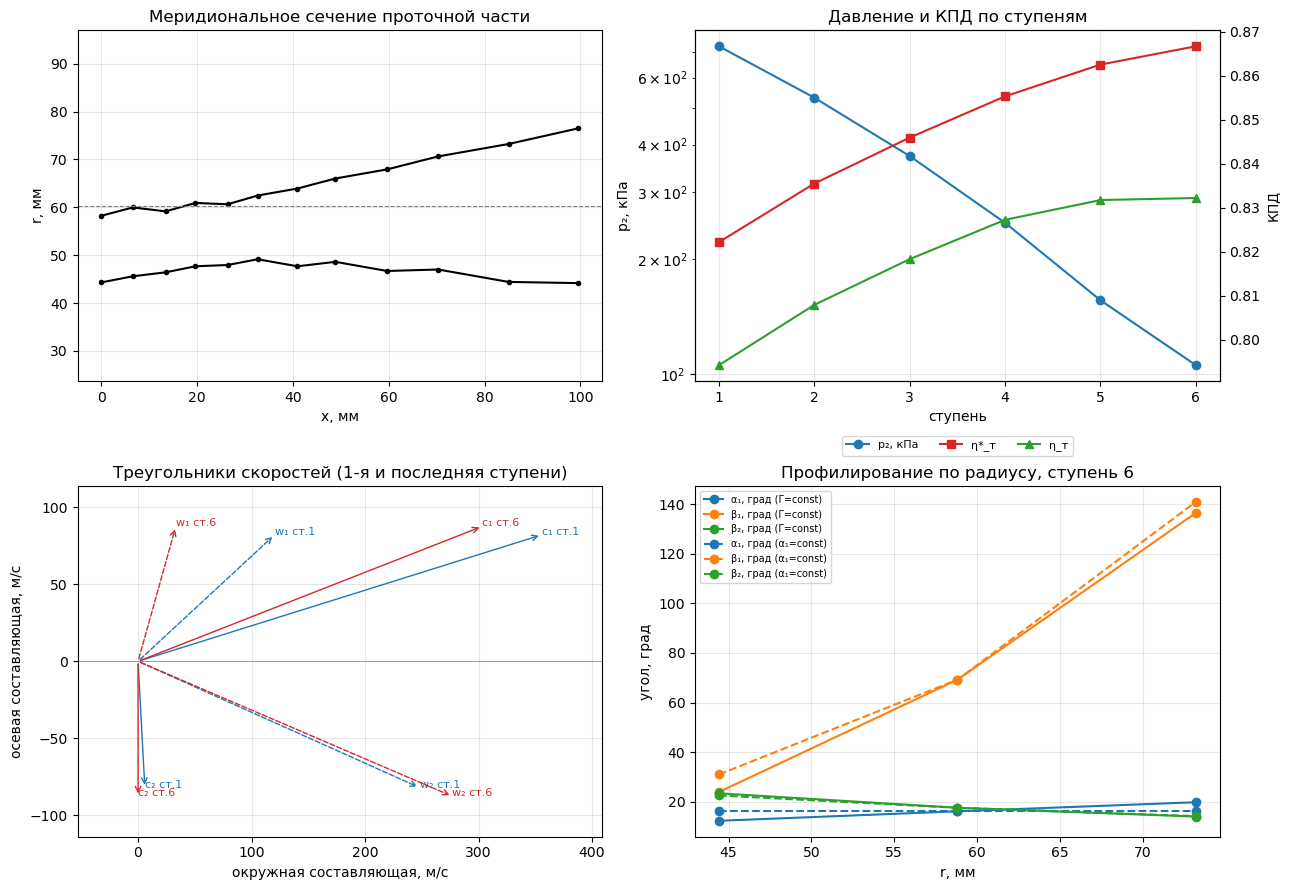

In [30]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
# 1. меридиональное сечение
a = ax[0, 0]
a.plot(контур_df.x * 1e3, контур_df.r_н * 1e3, "k-o", ms=3)
a.plot(контур_df.x * 1e3, контур_df.r_в * 1e3, "k-o", ms=3)
a.axhline(D_т / 2 * 1e3, color="gray", ls="--", lw=0.8)  # средний радиус
a.set(xlabel="x, мм", ylabel="r, мм", title="Меридиональное сечение проточной части")
a.set_aspect("equal", adjustable="datalim")  # без искажения пропорций
a.grid(alpha=0.3)
# 2. давление и температура по ступеням
a = ax[0, 1]
ид = np.arange(1, z + 1)
л_p, = a.plot(ид, [s["p2"] / 1e3 for s in ступени], "o-", color="tab:blue", label="p₂, кПа")
a.set(xlabel="ступень", ylabel="p₂, кПа", title="Давление и КПД по ступеням")
a.set_yscale("log")
a2 = a.twinx()
л_1, = a2.plot(ид, [s["η_т_п"] for s in ступени], "s-", color="tab:red", label="η*_т")
л_2, = a2.plot(ид, [s["η_т"] for s in ступени], "^-", color="tab:green", label="η_т")
a2.set_ylabel("КПД")
a.legend(handles=[л_p, л_1, л_2], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)
a.grid(alpha=0.3)
# 3. треугольники скоростей (первая и последняя ступень)
a = ax[1, 0]
точки_тр = [(0.0, 0.0)]
for j, (idx, цвет) in enumerate(((0, "tab:blue"), (len(ступени) - 1, "tab:red"))):
    s = ступени[idx]
    for (vx, vy, лаб, ls) in (
        (s["c1u"], s["c1a"], "c₁", "-"),
        (s["c1u"] - s["u1"], s["c1a"], "w₁", "--"),
    ):
        a.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=цвет, ls=ls))
        a.text(vx, vy, f"{лаб} ст.{idx+1}", color=цвет, fontsize=8)
        точки_тр.append((vx, vy))
    for (vx, vy, лаб, ls) in (
        (s["c2u"], -s["c2a"], "c₂", "-"),
        (s["c2u"] + s["u2"], -s["c2a"], "w₂", "--"),
    ):
        a.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=цвет, ls=ls))
        a.text(vx, vy, f"{лаб} ст.{idx+1}", color=цвет, fontsize=8)
        точки_тр.append((vx, vy))
a.plot(*zip(*точки_тр), ".", alpha=0)  # только для автомасштаба (annotate его не двигает)
a.margins(0.15)
a.set(xlabel="окружная составляющая, м/с", ylabel="осевая составляющая, м/с", title="Треугольники скоростей (1-я и последняя ступени)")
a.axhline(0, color="gray", lw=0.5)
a.grid(alpha=0.3)
# 4. углы по радиусу в последней ступени
a = ax[1, 1]
for м, ls in (("Γ", "-"), ("α1", "--")):
    df = профили[м][-1]
    for пар, цвет in (("α₁, град", "tab:blue"), ("β₁, град", "tab:orange"), ("β₂, град", "tab:green")):
        a.plot(df.loc["r, мм"], df.loc[пар], ls, color=цвет, marker="o", label=f"{пар} ({'Γ=const' if м=='Γ' else 'α₁=const'})")
a.set(xlabel="r, мм", ylabel="угол, град", title=f"Профилирование по радиусу, ступень {z}")
a.legend(fontsize=7)
a.grid(alpha=0.3)
fig.tight_layout()
plt.show()